In [1]:
import pandas as pd 
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATA_PATH = "C:/Sudeen/Customer-Risk-Intelligence/data/raw/telco_customer_churn.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset loaded Successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")


Dataset loaded Successfully!
Rows: 7043
Columns: 21


In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing %" : (df.isnull().mean()*100).round(2)
})

missing[missing["Missing Values"] > 0].sort_values(
    "Missing Values",
    ascending= False
)

,Missing Values,Missing %


In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [7]:
churn_counts = df["Churn"].value_counts()
print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [8]:
churn_percentage = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(churn_percentage)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [9]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [10]:
df["TotalCharges"].value_counts().head(20)

TotalCharges
20.2     11
         11
19.75     9
19.9      8
20.05     8
19.65     8
45.3      7
19.55     7
20.15     6
19.45     6
20.25     6
20.45     5
20.3      5
74.7      4
70.6      4
44        4
75.3      4
20.4      4
19.85     4
49.9      4
Name: count, dtype: int64

In [11]:
print("Blank TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())

Blank TotalCharges: 11


In [12]:
df.loc[
    df["TotalCharges"].str.strip() == "",
    ["customerID","tenure","MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [13]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [14]:
df.loc[
    df["TotalCharges"].isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [15]:
print("Missing TotalCharges after conversion:", df["TotalCharges"].isna().sum())

Missing TotalCharges after conversion: 11


In [16]:
df.loc[
    df["TotalCharges"].isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [17]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [18]:
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("TotalCharges data type:", df["TotalCharges"].dtype)

Missing TotalCharges: 0
TotalCharges data type: float64


In [19]:
df.loc[
    df["tenure"] == 0,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,0.0,No
753,3115-CZMZD,0,20.25,0.0,No
936,5709-LVOEQ,0,80.85,0.0,No
1082,4367-NUYAO,0,25.75,0.0,No
1340,1371-DWPAZ,0,56.05,0.0,No
3331,7644-OMVMY,0,19.85,0.0,No
3826,3213-VVOLG,0,25.35,0.0,No
4380,2520-SGTTA,0,20.00,0.0,No
5218,2923-ARZLG,0,19.70,0.0,No
6670,4075-WKNIU,0,73.35,0.0,No


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [21]:
df["ChurnFlag"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

df[["Churn", "ChurnFlag"]].head()

,Churn,ChurnFlag
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


In [22]:
churn_rate = df["ChurnFlag"].mean() * 100

print(f"Overall Churn Rate: {churn_rate:.2f}%")

Overall Churn Rate: 26.54%


In [23]:
contract_churn = (
    df.groupby("Contract")["ChurnFlag"]
        .mean()
        .mul(100)
        .round(2)
        .sort_values(ascending=False)
)

print(contract_churn)

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: ChurnFlag, dtype: float64


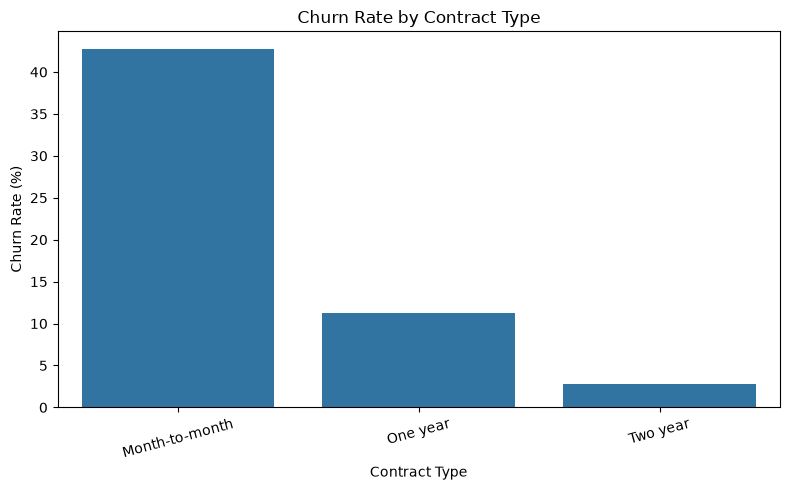

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [25]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1,6,12,24,48,72],
    labels=[
        "0–6 months",
        "7–12 months",
        "13–24 months",
        "25–48 months",
        "49–72 months"
    ]
)

In [26]:
tenure_churn = (
    df.groupby("TenureGroup", observed=True)["ChurnFlag"]
    .mean()
    .mul(100)
    .round(2)
)

print(tenure_churn)

TenureGroup
0–6 months      52.94
7–12 months     35.89
13–24 months    28.71
25–48 months    20.39
49–72 months     9.51
Name: ChurnFlag, dtype: float64


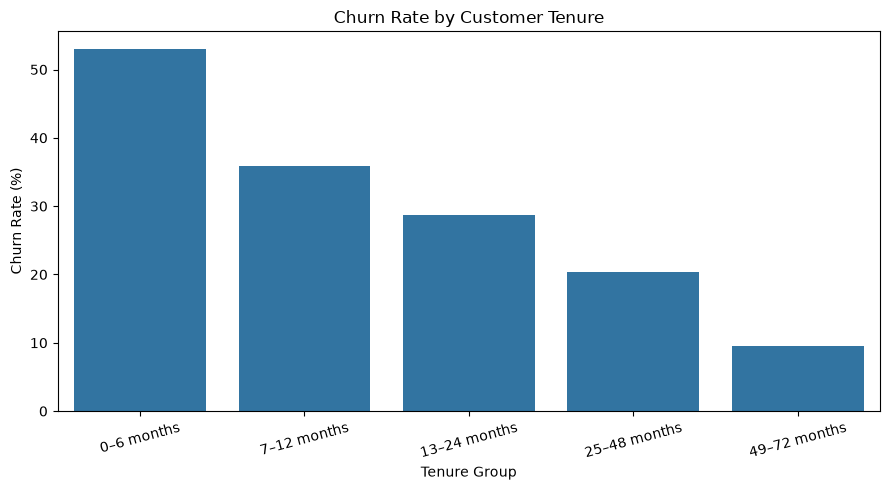

In [27]:
plt.figure(figsize=(9,5))
sns.barplot(
    x = tenure_churn.index,
    y = tenure_churn.values
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [28]:
df["MonthlyChargeGroup"] = pd.qcut(
    df["MonthlyCharges"],
    q=4,
    labels=[
        "Low",
        "Medium-Low",
        "Medium-High",
        "High"
    ]
)

In [29]:
charge_churn = (
    df.groupby("MonthlyChargeGroup", observed=True)["ChurnFlag"]
        .mean()
        .mul(100)
        .round(2)
)
print(charge_churn)


MonthlyChargeGroup
Low            11.24
Medium-Low     24.58
Medium-High    37.51
High           32.88
Name: ChurnFlag, dtype: float64


In [30]:
internet_churn = (
    df.groupby("InternetService")["ChurnFlag"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print(internet_churn)

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: ChurnFlag, dtype: float64


In [31]:
payment_churn = (
    df.groupby("PaymentMethod")["ChurnFlag"]
        .mean()
        .sort_values(ascending=False)
      * 100
)

print(payment_churn.round(2))

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: ChurnFlag, dtype: float64


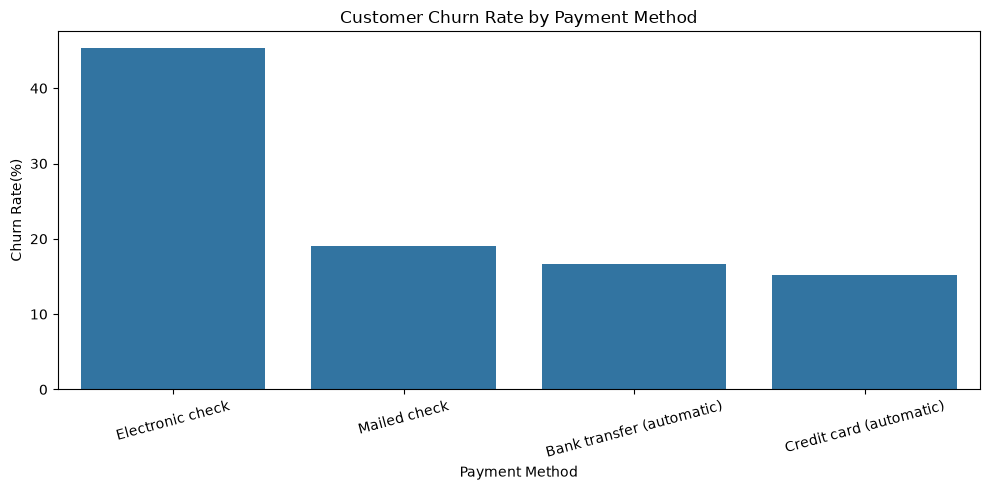

In [32]:
plt.figure(figsize=(10,5))

sns.barplot(
    x = payment_churn.index,
    y = payment_churn.values
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate(%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [33]:
df["AnnualRevenue"] = df["MonthlyCharges"] * 12

In [34]:
df["RevenueAtRisk"] = np.where(
    df["Churn"] == "Yes",
    df["AnnualRevenue"],
    0
)

In [35]:
print(f"Total Annual Revenue: ${df['AnnualRevenue'].sum():,.2f}")
print(f"Annual Revenue from Churned Customers: ${df['RevenueAtRisk'].sum():,.2f}")

Total Annual Revenue: $5,473,399.20
Annual Revenue from Churned Customers: $1,669,570.20


In [36]:
revenue_by_contract = (
    df.groupby("Contract")
        .agg(
            Customers = ("customerID", "count"),
            ChurnedCustomers=("ChurnFlag","sum"),
            AnnualRevenue=("AnnualRevenue","sum"),
            RevenueAtRisk=("RevenueAtRisk", "sum")
        )
)

revenue_by_contract["ChurnRate"] = (
    revenue_by_contract["ChurnedCustomers"]
    / revenue_by_contract["Customers"]
    * 100
).round(2)

revenue_by_contract

,Customers,ChurnedCustomers,AnnualRevenue,RevenueAtRisk,ChurnRate
Contract,,,,,
Month-to-month,3875,1655,3087529.8,1450165.2,42.71
One year,1473,166,1149799.2,169421.4,11.27
Two year,1695,48,1236070.2,49983.6,2.83


In [37]:
high_value_churn = (
    df[df["Churn"]== "Yes"]
    .sort_values("MonthlyCharges", ascending=False)
    [
        [
            "customerID",
            "tenure",
            "Contract",
            "InternetService",
            "PaymentMethod",
            "MonthlyCharges",
            "TotalCharges",
            "Churn"
        ]
    ]
)

high_value_churn.head(20)

,customerID,tenure,Contract,InternetService,PaymentMethod,MonthlyCharges,TotalCharges,Churn
5127,8199-ZLLSA,67,One year,Fiber optic,Bank transfer (automatic),118.35,7804.15,Yes
4610,2889-FPWRM,72,One year,Fiber optic,Bank transfer (automatic),117.80,8684.80,Yes
4875,2302-ANTDP,48,Month-to-month,Fiber optic,Electronic check,117.45,5438.90,Yes
6289,9053-JZFKV,67,Two year,Fiber optic,Credit card (automatic),116.20,7752.30,Yes
6537,1444-VVSGW,70,One year,Fiber optic,Credit card (automatic),115.65,7968.85,Yes
1306,0201-OAMXR,70,One year,Fiber optic,Credit card (automatic),115.55,8127.60,Yes
1077,4361-BKAXE,41,Month-to-month,Fiber optic,Bank transfer (automatic),114.50,4527.45,Yes
6038,1555-DJEQW,70,Two year,Fiber optic,Bank transfer (automatic),114.20,7723.90,Yes
1673,9158-VCTQB,41,Month-to-month,Fiber optic,Bank transfer (automatic),113.60,4594.95,Yes
1770,7279-BUYWN,41,Month-to-month,Fiber optic,Electronic check,113.20,4689.50,Yes


In [38]:
df["RiskScore"] = (
    (df["Contract"] == "Month-to-month").astype(int)
    + (df["tenure"] <= 6).astype(int)
    + (df["InternetService"] == "Fiber optic").astype(int)
    + (df["PaymentMethod"] == "Electronic check").astype(int)
    + (df["MonthlyCharges"] > df["MonthlyCharges"].median()).astype(int)
)

In [39]:
df["RiskLevel"] = pd.cut(
    df["RiskScore"],
    bins = [-1,1,3,5],
    labels=["Low","Medium","High"]
)

In [40]:
print(df["RiskLevel"].value_counts())

RiskLevel
Medium    2864
Low       2737
High      1442
Name: count, dtype: int64


In [41]:
print(df["RiskLevel"].value_counts())

RiskLevel
Medium    2864
Low       2737
High      1442
Name: count, dtype: int64


In [42]:
from sklearn.model_selection import train_test_split

X = df.drop(
    columns=[
        "customerID",
        "Churn",
        "ChurnFlag",
        "RiskScore",
        "RiskLevel",
        "TenureGroup",
        "MonthlyChargeGroup",
        "AnnualRevenue",
        "RevenueAtRisk"
    ]
)

y = df["ChurnFlag"]

print("Feature:", X.shape)
print("Target:" ,y.shape)

Feature: (7043, 19)
Target: (7043,)


In [43]:
print(X.columns.tolist())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [44]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining churn rate:", y_train.mean())
print("Testing samples:", y_test.mean())

Training samples: 5634
Testing samples: 1409

Training churn rate: 0.2653532126375577
Testing samples: 0.2654364797728886


In [45]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "string", "str", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal features:", len(numeric_features) + len(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total features: 19


In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline(
    steps=[
        ("scalar", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer,numeric_features),
        ("cat", categorical_transformer,categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [47]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps = [
        ("preprocessor",preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

In [48]:
logistic_model.fit(X_train, y_train)
print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_pred = logistic_model.predict(X_test)

y_proba = logistic_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print("Logistic Regression Performance")
print("=" * 40)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Performance
Accuracy : 0.7381
Precision: 0.5043
Recall   : 0.7834
F1 Score : 0.6136
ROC-AUC  : 0.8416

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Confusion Matrix:
[[747 288]
 [ 81 293]]


In [50]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=12,
                min_samples_split=10,
                min_samples_leaf=4,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [51]:
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [52]:
rf_pred = random_forest_model.predict(X_test)

rf_proba = random_forest_model.predict_proba(X_test)[:,1]

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_proba)

print("Random Forest Performance")
print("=" * 40)
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Performance
Accuracy : 0.7587
Precision: 0.5310
Recall   : 0.7781
F1 Score : 0.6312
ROC-AUC  : 0.8399

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409


Confusion Matrix:
[[778 257]
 [ 83 291]]


In [53]:
rf_classifier = random_forest_model.named_steps["classifier"]

rf_preprocessor = random_forest_model.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
36,cat__Contract_Month-to-month,0.128843
1,num__tenure,0.124417
3,num__TotalCharges,0.101414
2,num__MonthlyCharges,0.070706
38,cat__Contract_Two year,0.064518
18,cat__OnlineSecurity_No,0.060083
16,cat__InternetService_Fiber optic,0.050261
27,cat__TechSupport_No,0.048095
43,cat__PaymentMethod_Electronic check,0.036226
37,cat__Contract_One year,0.020525


In [54]:
df["ChurnProbability"] = random_forest_model.predict_proba(X)[:,1]

print(df[
    ["customerID", "ChurnProbability", "Churn"]
].head(10))

   customerID  ChurnProbability Churn
0  7590-VHVEG          0.697969    No
1  5575-GNVDE          0.081108    No
2  3668-QPYBK          0.717327   Yes
3  7795-CFOCW          0.046284    No
4  9237-HQITU          0.835949   Yes
5  9305-CDSKC          0.957923   Yes
6  1452-KIOVK          0.672564    No
7  6713-OKOMC          0.363049    No
8  7892-POOKP          0.819396   Yes
9  6388-TABGU          0.073219    No


In [55]:
df["MLRiskLevel"] = pd.cut(
    df["ChurnProbability"],
    bins=[-0.01, 0.30, 0.60, 1.00],
    labels=["Low","Medium","High"]
)

print(df["MLRiskLevel"].value_counts())

MLRiskLevel
Low       3262
High      2116
Medium    1665
Name: count, dtype: int64


In [56]:
ml_risk_performance = (
    df.groupby("MLRiskLevel", observed=True)["ChurnFlag"]
        .mean()
        .mul(100)
        .round(2)
)

print("Actual Churn Rate by ML Risk Level")
print("=" * 40)
print(ml_risk_performance)

Actual Churn Rate by ML Risk Level
MLRiskLevel
Low        1.69
Medium    21.62
High      68.71
Name: ChurnFlag, dtype: float64


In [57]:
df["RevenueAtRisk"] = (
    df["MonthlyCharges"] * df["ChurnProbability"]
)

In [58]:
total_revenue_at_risk = df["RevenueAtRisk"].sum()

print(
    f"Total Expected Monthly Revenue at Risk: "
    f"{total_revenue_at_risk:,.2f}"
)

Total Expected Monthly Revenue at Risk: 202,507.30


In [59]:
revenue_by_risk = (
    df.groupby("MLRiskLevel", observed=True)["RevenueAtRisk"]
        .agg(["sum", "mean", "count"])
        .round(2)
)

print(revenue_by_risk)

                   sum   mean  count
MLRiskLevel                         
Low           22781.92   6.98   3262
Medium        53651.80  32.22   1665
High         126073.57  59.58   2116


In [60]:
df["RevenueRiskScore"] = (
    df["RevenueAtRisk"] / df["RevenueAtRisk"].max()
)

df["RetentionPriorityScore"] = (
    0.6 * df["ChurnProbability"]
    + 0.4 * df["RevenueRiskScore"]
)

print(
    df[
        [
            "customerID",
            "ChurnProbability",
            "MLRiskLevel",
            "MonthlyCharges",
            "RevenueAtRisk",
            "RetentionPriorityScore"
        ]
    ]
    .sort_values("RetentionPriorityScore", ascending=False)
    .head(20)
)

      customerID  ChurnProbability MLRiskLevel  MonthlyCharges  RevenueAtRisk  \
6482  5419-JPRRN          0.960975        High          101.45      97.490907   
2208  7216-EWTRS          0.958449        High          100.80      96.611659   
6232  9681-OXGVC          0.955334        High          100.50      96.011059   
5     9305-CDSKC          0.957923        High           99.65      95.457026   
1026  4822-RVYBB          0.952019        High          100.60      95.773114   
2797  6023-YEBUP          0.949159        High          100.95      95.817591   
905   0781-LKXBR          0.949838        High          100.50      95.458761   
3830  2656-TABEH          0.950294        High          100.20      95.219480   
4517  2012-NWRPA          0.948058        High           99.55      94.379131   
4800  9300-AGZNL          0.969786        High           94.00      91.159875   
6866  0295-PPHDO          0.963469        High           95.45      91.963072   
6365  8884-ADFVN          0.

In [61]:
df["RetentionPriority"] = pd.qcut(
    df["RetentionPriorityScore"],
    q=[0, 0.50, 0.80, 0.95, 1.00],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Critical"
    ],
    duplicates="drop"
)

print(df["RetentionPriority"].value_counts())

RetentionPriority
Low         3522
Moderate    2112
High        1056
Critical     353
Name: count, dtype: int64


In [62]:
critical_customers = df[
    df["RetentionPriority"] == "Critical"
].copy()

print("Critical Customers:", len(critical_customers))

print(
    critical_customers[
        [
            "customerID",
            "tenure",
            "Contract",
            "InternetService",
            "MonthlyCharges",
            "ChurnProbability",
            "RevenueAtRisk",
            "RetentionPriorityScore"
        ]
    ]
    .head(20)
)

Critical Customers: 353
     customerID  tenure        Contract InternetService  MonthlyCharges  \
5    9305-CDSKC       8  Month-to-month     Fiber optic           99.65   
8    7892-POOKP      28  Month-to-month     Fiber optic          104.80   
39   8168-UQWWF      11  Month-to-month     Fiber optic           97.85   
55   1658-BYGOY      18  Month-to-month     Fiber optic           95.45   
64   5698-BQJOH       9  Month-to-month     Fiber optic           94.40   
80   5919-TMRGD       1  Month-to-month     Fiber optic           79.35   
85   4445-ZJNMU       9  Month-to-month     Fiber optic           99.30   
117  5299-RULOA      10  Month-to-month     Fiber optic          100.25   
151  3874-EQOEP       7  Month-to-month     Fiber optic           95.00   
171  1875-QIVME       2  Month-to-month     Fiber optic          104.40   
191  2472-OVKUP       6  Month-to-month     Fiber optic           91.00   
207  1285-OKIPP       1  Month-to-month     Fiber optic           79.90   
2

In [63]:
priority_performance = (
    df.groupby("RetentionPriority", observed=True)["ChurnFlag"]
        .agg(["mean", "count"])
)

priority_performance["ChurnRate"] = (
    priority_performance["mean"] * 100
).round(2)

print(priority_performance)

                       mean  count  ChurnRate
RetentionPriority                            
Low                0.027541   3522       2.75
Moderate           0.339962   2112      34.00
High               0.690341   1056      69.03
Critical           0.920680    353      92.07


In [64]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [65]:
rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_classifier = random_forest_model.named_steps["classifier"]

X_transformed = rf_preprocessor.transform(X)

print("Original X shape:", X.shape)
print("Transformed X shape:", X_transformed.shape)

Original X shape: (7043, 19)
Transformed X shape: (7043, 45)


In [66]:
feature_names = rf_preprocessor.get_feature_names_out()

print("Number of feature names:", len(feature_names))
print("\nFirst 20 features:")
print(feature_names[:20])

Number of feature names: 45

First 20 features:
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Female' 'cat__gender_Male'
 'cat__Partner_No' 'cat__Partner_Yes' 'cat__Dependents_No'
 'cat__Dependents_Yes' 'cat__PhoneService_No' 'cat__PhoneService_Yes'
 'cat__MultipleLines_No' 'cat__MultipleLines_No phone service'
 'cat__MultipleLines_Yes' 'cat__InternetService_DSL'
 'cat__InternetService_Fiber optic' 'cat__InternetService_No'
 'cat__OnlineSecurity_No' 'cat__OnlineSecurity_No internet service']


In [67]:
explainer = shap.TreeExplainer(rf_classifier)

print("SHAP TreeExplainer created successfully!")

SHAP TreeExplainer created successfully!


In [68]:
X_shap = X_transformed[:500]

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (500, 45)


In [69]:
shap_values = explainer.shap_values(X_shap)

print("SHAP calculation completed!")

SHAP calculation completed!


In [70]:
print(type(shap_values))

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    for i, sv in enumerate(shap_values):
        print(f"Class {i} shape:", sv.shape)
else:
    
    print("SHAP shape:", shap_values.shape)

<class 'numpy.ndarray'>
SHAP shape: (500, 45, 2)


In [71]:
shap_values_churn = shap_values[:, :, 1]

print("Churn SHAP shape:", shap_values_churn.shape)

Churn SHAP shape: (500, 45)


In [72]:
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "MeanAbsSHAP": np.abs(shap_values_churn).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "MeanAbsSHAP",
    ascending=False
)

print(shap_importance.head(20).to_string(index=False))

                                 Feature  MeanAbsSHAP
            cat__Contract_Month-to-month     0.075856
                             num__tenure     0.055030
        cat__InternetService_Fiber optic     0.045534
                  cat__Contract_Two year     0.037513
                  cat__OnlineSecurity_No     0.035194
                       num__TotalCharges     0.032957
                     cat__TechSupport_No     0.028736
     cat__PaymentMethod_Electronic check     0.025919
                     num__MonthlyCharges     0.019158
                cat__InternetService_DSL     0.016667
                    cat__OnlineBackup_No     0.011721
                 cat__OnlineSecurity_Yes     0.010314
                  cat__Contract_One year     0.010058
               cat__PaperlessBilling_Yes     0.010010
                cat__PaperlessBilling_No     0.009987
cat__StreamingMovies_No internet service     0.008586
                    cat__TechSupport_Yes     0.008513
                cat__Streami

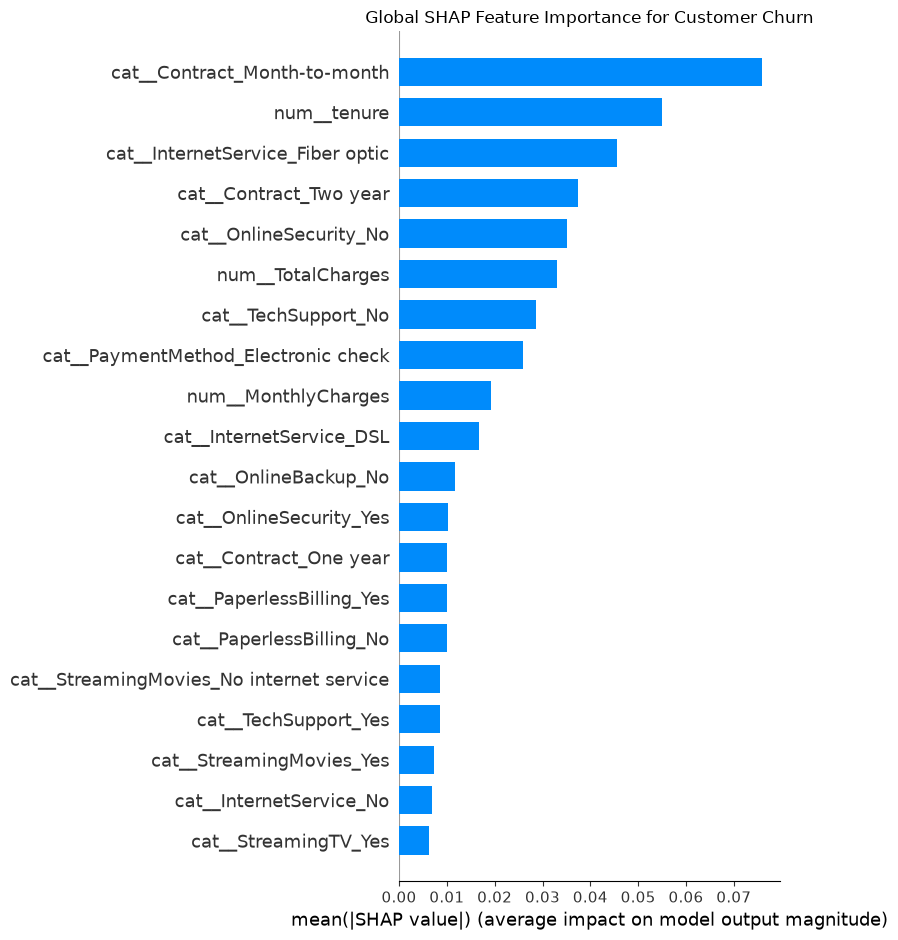

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values_churn,
    X_shap,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title("Global SHAP Feature Importance for Customer Churn")
plt.tight_layout()
plt.show()

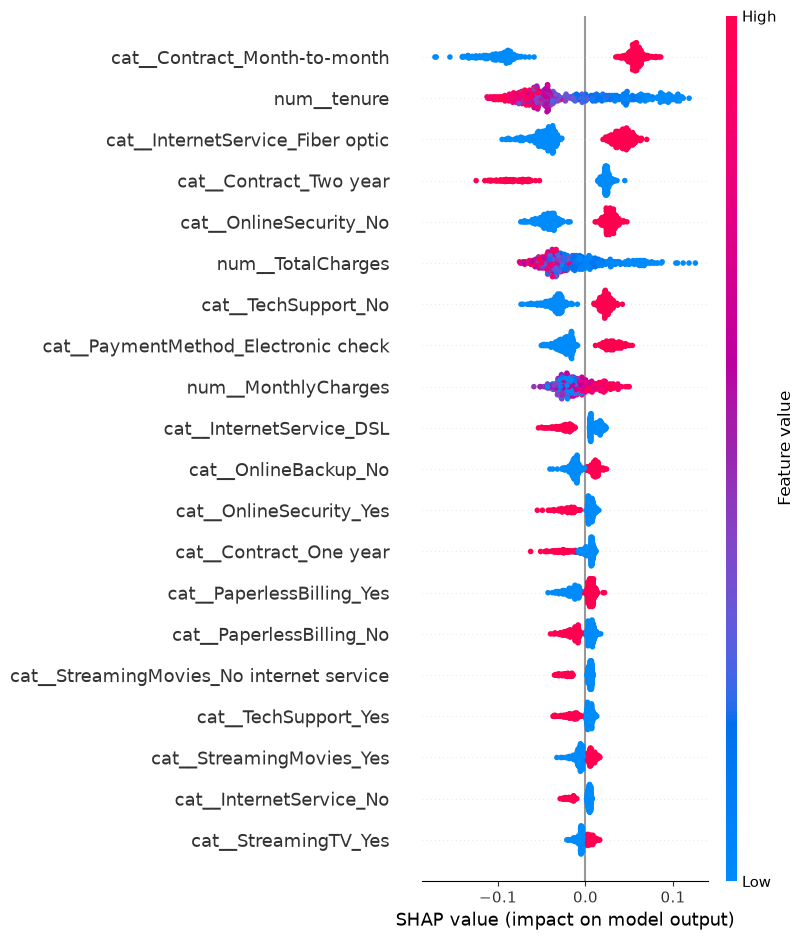

In [74]:
shap.summary_plot(
    shap_values_churn,
    X_shap,
    feature_names=feature_names
)

In [75]:
customer_id = "9305-CDSKC"

customer_index = df.index[df["customerID"] == customer_id][0]

print("Customer index:", customer_index)

Customer index: 5


In [76]:
customer_position = list(X.index[:500]).index(customer_index)

print("SHAP sample position:", customer_position)

SHAP sample position: 5


In [77]:
customer_shap = pd.DataFrame({
    "Feature": feature_names,
    "SHAPValue": shap_values_churn[customer_position],
    "FeatureValue": X_shap[customer_position]
})

customer_shap["AbsSHAP"] = (
    customer_shap["SHAPValue"].abs()
)

customer_shap = customer_shap.sort_values(
    "AbsSHAP",
    ascending=False
)

print(
    customer_shap.head(15).to_string(index=False)
)

                            Feature  SHAPValue  FeatureValue  AbsSHAP
       cat__Contract_Month-to-month   0.056141      1.000000 0.056141
   cat__InternetService_Fiber optic   0.051688      1.000000 0.051688
                        num__tenure   0.049429     -0.996684 0.049429
             cat__OnlineSecurity_No   0.028438      1.000000 0.028438
                num__MonthlyCharges   0.027865      1.152133 0.027865
                cat__TechSupport_No   0.024031      1.000000 0.024031
cat__PaymentMethod_Electronic check   0.023912      1.000000 0.023912
             cat__Contract_Two year   0.023505      0.000000 0.023505
           cat__InternetService_DSL   0.017738      0.000000 0.017738
               cat__OnlineBackup_No   0.012877      1.000000 0.012877
                  num__TotalCharges   0.012524     -0.648896 0.012524
             cat__MultipleLines_Yes   0.009684      1.000000 0.009684
           cat__StreamingMovies_Yes   0.009026      1.000000 0.009026
          cat__Paper

In [78]:
customer_profile = df[
    df["customerID"] == "9305-CDSKC"
][[
    "customerID",
    "tenure",
    "Contract",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaymentMethod",
    "MonthlyCharges",
    "ChurnProbability",
    "MLRiskLevel",
    "RevenueAtRisk",
    "RetentionPriorityScore",
    "RetentionPriority",
    "Churn"
]]

print(customer_profile.T)

                                       5
customerID                    9305-CDSKC
tenure                                 8
Contract                  Month-to-month
InternetService              Fiber optic
OnlineSecurity                        No
TechSupport                           No
PaymentMethod           Electronic check
MonthlyCharges                     99.65
ChurnProbability                0.957923
MLRiskLevel                         High
RevenueAtRisk                  95.457026
RetentionPriorityScore          0.966409
RetentionPriority               Critical
Churn                                Yes


In [79]:
top_risk_drivers = customer_shap[
    customer_shap["SHAPValue"] > 0
].head(7)

print(
    top_risk_drivers[
        ["Feature", "SHAPValue"]
    ].to_string(index=False)
)

                            Feature  SHAPValue
       cat__Contract_Month-to-month   0.056141
   cat__InternetService_Fiber optic   0.051688
                        num__tenure   0.049429
             cat__OnlineSecurity_No   0.028438
                num__MonthlyCharges   0.027865
                cat__TechSupport_No   0.024031
cat__PaymentMethod_Electronic check   0.023912


In [80]:
from sklearn.model_selection import train_test_split

X_research = df.drop(
    columns=["customerID", "Churn", "ChurnFlag",
            "ChurnProbability", "MLRiskLevel",
            "RevenueAtRisk", "RevenueRiskScore",
            "RetentionPriorityScore", "RetentionPriority"],
    errors="ignore"
)

y_research = df["ChurnFlag"]

X_train_research, X_test_research, y_train_research, y_test_research = train_test_split(
    X_research,
    y_research,
    test_size=0.20,
    random_state=42,
    stratify=y_research
)

print("Training samples:", X_train_research.shape)
print("Testing samples:", X_test_research.shape)

Training samples: (5634, 24)
Testing samples: (1409, 24)


In [81]:
print("Research features:")
print(X_research.columns.tolist())
print("\nNumber of features:", X_research.shape[1])

Research features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TenureGroup', 'MonthlyChargeGroup', 'AnnualRevenue', 'RiskScore', 'RiskLevel']

Number of features: 24


In [82]:
research_drop = [
    "customerID",
    "Churn",
    "ChurnFlag",
    "ChurnProbability",
    "MLRiskLevel",
    "RevenueAtRisk",
    "RevenueRiskScore",
    "RetentionPriorityScore",
    "RetentionPriority",
    "RiskScore",
    "RiskLevel"
]

X_research = df.drop(
    columns=research_drop,
    errors="ignore"
)

y_research = df["ChurnFlag"]

print("Research features:")
print(X_research.columns.tolist())

print("\nNumber of features:", X_research.shape[1])

Research features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TenureGroup', 'MonthlyChargeGroup', 'AnnualRevenue']

Number of features: 22


In [83]:
from sklearn.model_selection import train_test_split

X_train_research, X_test_research, y_train_research, y_test_research = train_test_split(
    X_research,
    y_research,
    test_size=0.20,
    random_state=42,
    stratify=y_research
)

print("Training:", X_train_research.shape)
print("Testing :", X_test_research.shape)

Training: (5634, 22)
Testing : (1409, 22)


In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

numeric_features_research = X_train_research.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features_research = X_train_research.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features_research)

print("\nCategorical features:")
print(categorical_features_research)

numeric_transformer_research = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer_research = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor_research = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_research, numeric_features_research),
        ("cat", categorical_transformer_research, categorical_features_research)
    ]
)

rf_research = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

research_rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_research),
        ("classifier", rf_research)
    ]
)

print("\nResearch Random Forest pipeline created successfully!")

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AnnualRevenue']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup', 'MonthlyChargeGroup']

Research Random Forest pipeline created successfully!


In [85]:
research_rf_pipeline.fit(
    X_train_research,
    y_train_research
)

print("Research Random Forest trained successfully!")

Research Random Forest trained successfully!


In [86]:
y_test_pred = research_rf_pipeline.predict(X_test_research)

y_test_proba = research_rf_pipeline.predict_proba(
    X_test_research
)[:, 1]

print("Predictions generated successfully!")

print("Prediction shape:", y_test_pred.shape)
print("Probability shape:", y_test_proba.shape)

print("\nFirst 10 churn probabilities:")
print(y_test_proba[:10])

Predictions generated successfully!
Prediction shape: (1409,)
Probability shape: (1409,)

First 10 churn probabilities:
[0.01092087 0.85757448 0.14414153 0.48325232 0.03912058 0.71843835
 0.57565523 0.2135558  0.01986179 0.56215603]


In [87]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test_research, y_test_pred)
precision = precision_score(y_test_research, y_test_pred)
recall = recall_score(y_test_research, y_test_pred)
f1 = f1_score(y_test_research, y_test_pred)
roc_auc = roc_auc_score(y_test_research, y_test_proba)

print("Research Random Forest Performance")
print("----------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_research, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_research, y_test_pred))

Research Random Forest Performance
----------------------------------
Accuracy : 0.7679
Precision: 0.5475
Recall   : 0.7246
F1 Score : 0.6237
ROC-AUC  : 0.8347

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.78      0.83      1035
           1       0.55      0.72      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409


Confusion Matrix:
[[811 224]
 [103 271]]


In [88]:
from sklearn.linear_model import LogisticRegression

logistic_research = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

logistic_research_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_research),
        ("classifier", logistic_research)
    ]
)

logistic_research_pipeline.fit(
    X_train_research,
    y_train_research
)

print("Research Logistic Regression trained successfully!")

Research Logistic Regression trained successfully!


In [89]:
y_lr_pred = logistic_research_pipeline.predict(
    X_test_research
)

y_lr_proba = logistic_research_pipeline.predict_proba(
    X_test_research
)[:, 1]

lr_accuracy = accuracy_score(
    y_test_research, y_lr_pred
)

lr_precision = precision_score(
    y_test_research, y_lr_pred
)

lr_recall = recall_score(
    y_test_research, y_lr_pred
)

lr_f1 = f1_score(
    y_test_research, y_lr_pred
)

lr_roc_auc = roc_auc_score(
    y_test_research, y_lr_proba
)

print("Research Logistic Regression Performance")
print("----------------------------------------")
print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1 Score : {lr_f1:.4f}")
print(f"ROC-AUC  : {lr_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_research, y_lr_pred))

Research Logistic Regression Performance
----------------------------------------
Accuracy : 0.7402
Precision: 0.5068
Recall   : 0.8021
F1 Score : 0.6211
ROC-AUC  : 0.8446

Confusion Matrix:
[[743 292]
 [ 74 300]]


In [90]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.20, 0.81, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (
        y_test_proba >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_research,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_research,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_test_research,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(
    threshold_df.round(4).to_string(index=False)
)

 Threshold  Precision  Recall     F1
      0.20     0.3973  0.9305 0.5568
      0.25     0.4315  0.9091 0.5852
      0.30     0.4566  0.8850 0.6024
      0.35     0.4832  0.8476 0.6155
      0.40     0.5050  0.8102 0.6222
      0.45     0.5245  0.7727 0.6249
      0.50     0.5475  0.7246 0.6237
      0.55     0.5708  0.6791 0.6203
      0.60     0.5844  0.6016 0.5929
      0.65     0.6154  0.5134 0.5598
      0.70     0.6614  0.4492 0.5350
      0.75     0.6971  0.3877 0.4983
      0.80     0.7405  0.3128 0.4398


In [91]:
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        lr_accuracy,
        accuracy
    ],
    "Precision": [
        lr_precision,
        precision
    ],
    "Recall": [
        lr_recall,
        recall
    ],
    "F1": [
        lr_f1,
        f1
    ],
    "ROC-AUC": [
        lr_roc_auc,
        roc_auc
    ]
})

print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression    0.7402     0.5068  0.8021 0.6211   0.8446
      Random Forest    0.7679     0.5475  0.7246 0.6237   0.8347


In [92]:
research_test_results = X_test_research.copy()

research_test_results["ActualChurn"] = y_test_research.values

research_test_results["ChurnProbability"] = y_test_proba

research_test_results["PredictedChurn"] = (
    y_test_proba >= 0.45
).astype(int)

print(research_test_results[
    ["ActualChurn", "ChurnProbability", "PredictedChurn"]
].head(10))

      ActualChurn  ChurnProbability  PredictedChurn
437             0          0.010921               0
2280            0          0.857574               1
2235            0          0.144142               0
4460            0          0.483252               1
3761            0          0.039121               0
5748            0          0.718438               1
3568            0          0.575655               1
2976            0          0.213556               0
5928            0          0.019862               0
1639            1          0.562156               1


In [93]:
research_test_results["RiskLevel"] = pd.cut(
    research_test_results["ChurnProbability"],
    bins=[-0.01, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

print(
    research_test_results["RiskLevel"]
    .value_counts()
)

RiskLevel
Low       684
High      385
Medium    340
Name: count, dtype: int64


In [94]:
research_test_results["MonthlyCharges"] = X_test_research[
    "MonthlyCharges"
].values

research_test_results["RevenueAtRisk"] = (
    research_test_results["ChurnProbability"]
    * research_test_results["MonthlyCharges"]
)

print(
    research_test_results[
        [
            "ChurnProbability",
            "MonthlyCharges",
            "RevenueAtRisk"
        ]
    ].head(10)
)

      ChurnProbability  MonthlyCharges  RevenueAtRisk
437           0.010921          114.05       1.245526
2280          0.857574          100.15      85.886084
2235          0.144142           78.35      11.293489
4460          0.483252           78.20      37.790332
3761          0.039121           82.65       3.233316
5748          0.718438           99.85      71.736069
3568          0.575655           99.15      57.076217
2976          0.213556           24.10       5.146695
5928          0.019862           19.75       0.392270
1639          0.562156           45.05      25.325129


In [95]:
total_test_revenue_at_risk = (
    research_test_results["RevenueAtRisk"].sum()
)

print(
    f"Expected Monthly Revenue at Risk: "
    f"${total_test_revenue_at_risk:,.2f}"
)

Expected Monthly Revenue at Risk: $38,148.37


In [96]:
revenue_by_risk = research_test_results.groupby(
    "RiskLevel",
    observed=True
)["RevenueAtRisk"].agg(
    ["sum", "mean", "count"]
)

print(
    revenue_by_risk.round(2)
)

                sum   mean  count
RiskLevel                        
Low         4735.67   6.92    684
Medium     10852.33  31.92    340
High       22560.37  58.60    385


In [97]:
risk_validation = research_test_results.groupby(
    "RiskLevel",
    observed=True
)["ActualChurn"].agg(
    ["mean", "sum", "count"]
)

risk_validation["ChurnRate"] = (
    risk_validation["mean"] * 100
)

print(
    risk_validation[
        ["count", "sum", "ChurnRate"]
    ].round(2)
)

           count  sum  ChurnRate
RiskLevel                       
Low          684   43       6.29
Medium       340  106      31.18
High         385  225      58.44


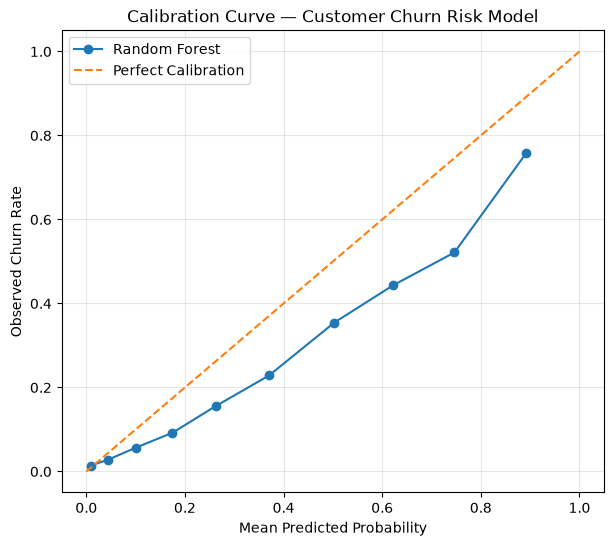

In [98]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    research_test_results["ActualChurn"],
    research_test_results["ChurnProbability"],
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Churn Rate")
plt.title("Calibration Curve — Customer Churn Risk Model")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [99]:
from sklearn.metrics import brier_score_loss

brier_score = brier_score_loss(
    research_test_results["ActualChurn"],
    research_test_results["ChurnProbability"]
)

print(f"Brier Score: {brier_score:.4f}")

Brier Score: 0.1553


In [100]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(
    research_test_results["ActualChurn"],
    research_test_results["ChurnProbability"]
)

print(f"PR-AUC: {pr_auc:.4f}")

PR-AUC: 0.6350


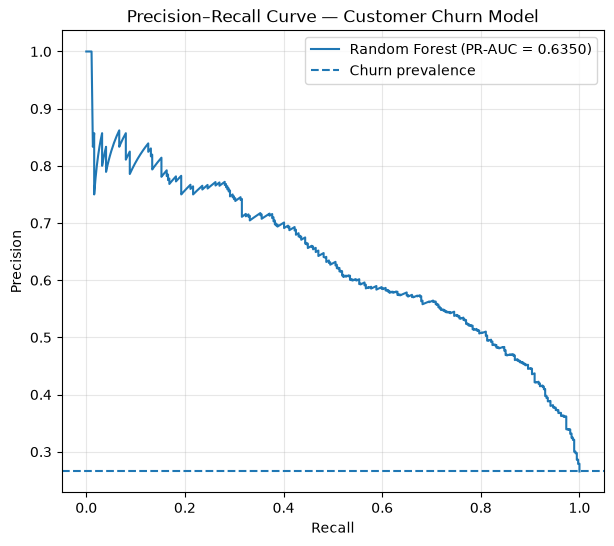

In [101]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    research_test_results["ActualChurn"],
    research_test_results["ChurnProbability"]
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Random Forest (PR-AUC = {pr_auc:.4f})"
)

plt.axhline(
    research_test_results["ActualChurn"].mean(),
    linestyle="--",
    label="Churn prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Customer Churn Model")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [102]:
lr_research_proba = logistic_research_pipeline.predict_proba(
    X_test_research
)[:, 1]

print("Logistic Regression probabilities generated successfully!")
print("Number of predictions:", len(lr_research_proba))

Logistic Regression probabilities generated successfully!
Number of predictions: 1409


In [103]:
from sklearn.metrics import average_precision_score, brier_score_loss

lr_pr_auc = average_precision_score(
    y_test_research,
    lr_research_proba
)

lr_brier = brier_score_loss(
    y_test_research,
    lr_research_proba
)

print(f"Logistic Regression PR-AUC: {lr_pr_auc:.4f}")
print(f"Logistic Regression Brier Score: {lr_brier:.4f}")

Logistic Regression PR-AUC: 0.6494
Logistic Regression Brier Score: 0.1660


In [104]:
import pandas as pd
import numpy as np

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:

    predicted_churn = (
        research_test_results["ChurnProbability"] >= threshold
    ).astype(int)

    targeted = predicted_churn == 1

    actual_churners_targeted = (
        (predicted_churn == 1) &
        (research_test_results["ActualChurn"] == 1)
    ).sum()

    total_actual_churners = (
        research_test_results["ActualChurn"] == 1
    ).sum()

    customers_targeted = targeted.sum()

    revenue_at_risk_targeted = (
        research_test_results.loc[
            targeted,
            "RevenueAtRisk"
        ].sum()
    )

    threshold_results.append({
        "Threshold": threshold,
        "CustomersTargeted": customers_targeted,
        "ActualChurnersTargeted": actual_churners_targeted,
        "ChurnersCapturedPct":
            actual_churners_targeted / total_actual_churners * 100,
        "RevenueAtRiskTargeted": revenue_at_risk_targeted
    })

threshold_analysis = pd.DataFrame(threshold_results)

threshold_analysis

,Threshold,CustomersTargeted,ActualChurnersTargeted,ChurnersCapturedPct,RevenueAtRiskTargeted
0,0.30,725,331,88.502674,33412.694647
1,0.35,656,317,84.759358,31766.667190
2,0.40,600,303,81.016043,30178.869117
3,0.45,551,289,77.272727,28754.889817
4,0.50,495,271,72.459893,26849.212491
5,0.55,445,254,67.914439,25001.393895
6,0.60,385,225,60.160428,22560.365532


In [105]:
threshold_analysis["ChurnersPer100Targeted"] = (
    threshold_analysis["ActualChurnersTargeted"]
    / threshold_analysis["CustomersTargeted"]
    * 100
)

print(
    threshold_analysis[
        [
            "Threshold",
            "CustomersTargeted",
            "ActualChurnersTargeted",
            "ChurnersCapturedPct",
            "ChurnersPer100Targeted",
            "RevenueAtRiskTargeted"
        ]
    ].round(2)
)

   Threshold  CustomersTargeted  ActualChurnersTargeted  ChurnersCapturedPct  \
0       0.30                725                     331                88.50   
1       0.35                656                     317                84.76   
2       0.40                600                     303                81.02   
3       0.45                551                     289                77.27   
4       0.50                495                     271                72.46   
5       0.55                445                     254                67.91   
6       0.60                385                     225                60.16   

   ChurnersPer100Targeted  RevenueAtRiskTargeted  
0                   45.66               33412.69  
1                   48.32               31766.67  
2                   50.50               30178.87  
3                   52.45               28754.89  
4                   54.75               26849.21  
5                   57.08               25001.39  
6 

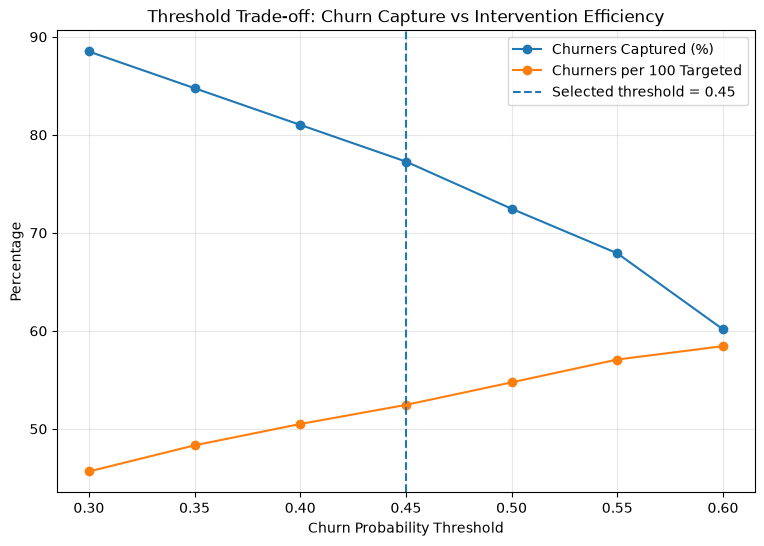

In [106]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_analysis["Threshold"],
    threshold_analysis["ChurnersCapturedPct"],
    marker="o",
    label="Churners Captured (%)"
)

plt.plot(
    threshold_analysis["Threshold"],
    threshold_analysis["ChurnersPer100Targeted"],
    marker="o",
    label="Churners per 100 Targeted"
)

plt.axvline(
    0.45,
    linestyle="--",
    label="Selected threshold = 0.45"
)

plt.xlabel("Churn Probability Threshold")
plt.ylabel("Percentage")
plt.title("Threshold Trade-off: Churn Capture vs Intervention Efficiency")
plt.xticks(threshold_analysis["Threshold"])
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [107]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_research_rf = CalibratedClassifierCV(
    research_rf_pipeline,
    method="sigmoid",
    cv=5
)

print("Calibrated Random Forest created successfully!")

Calibrated Random Forest created successfully!


In [108]:
calibrated_research_rf.fit(X_train_research, y_train_research)

print("Calibrated Random Forest trained successfully!")

Calibrated Random Forest trained successfully!


In [109]:
calibrated_rf_proba = calibrated_research_rf.predict_proba(
    X_test_research
)[:, 1]

print("Calibrated probabilities generated successfully!")
print("Number of predictions:", len(calibrated_rf_proba))

Calibrated probabilities generated successfully!
Number of predictions: 1409


In [110]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

calibrated_roc_auc = roc_auc_score(
    y_test_research,
    calibrated_rf_proba
)

calibrated_pr_auc = average_precision_score(
    y_test_research,
    calibrated_rf_proba
)

calibrated_brier = brier_score_loss(
    y_test_research,
    calibrated_rf_proba
)

print("Calibrated Random Forest")
print("-" * 35)
print(f"ROC-AUC : {calibrated_roc_auc:.4f}")
print(f"PR-AUC  : {calibrated_pr_auc:.4f}")
print(f"Brier   : {calibrated_brier:.4f}")

Calibrated Random Forest
-----------------------------------
ROC-AUC : 0.8384
PR-AUC  : 0.6430
Brier   : 0.1385


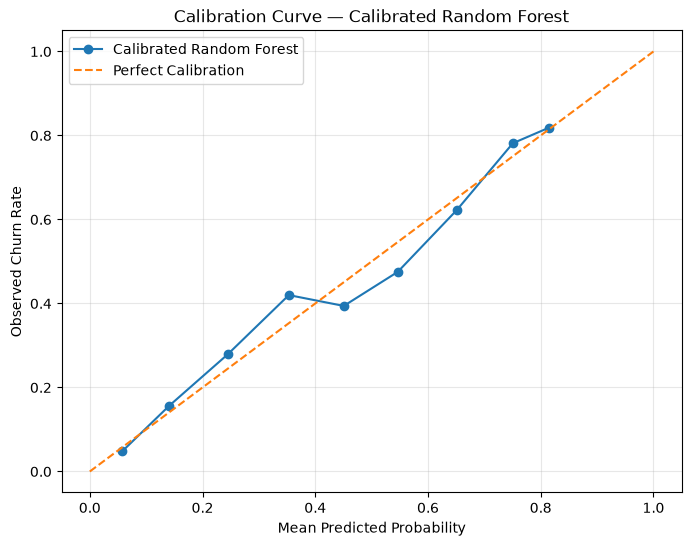

In [111]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true_cal, prob_pred_cal = calibration_curve(
    y_test_research,
    calibrated_rf_proba,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred_cal,
    prob_true_cal,
    marker="o",
    label="Calibrated Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Churn Rate")

plt.title(
    "Calibration Curve — Calibrated Random Forest"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [112]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Calibrated Random Forest"
    ],
    "Accuracy": [
        0.7402,
        0.7679,
        accuracy_score(y_test_research, calibrated_research_rf.predict(X_test_research))
    ],
    "Precision": [
        0.5068,
        0.5475,
        precision_score(
            y_test_research,
            calibrated_research_rf.predict(X_test_research)
        )
    ],
    "Recall": [
        0.8021,
        0.7246,
        recall_score(
            y_test_research,
            calibrated_research_rf.predict(X_test_research)
        )
    ],
    "F1": [
        0.6211,
        0.6237,
        f1_score(
            y_test_research,
            calibrated_research_rf.predict(X_test_research)
        )
    ],
    "ROC-AUC": [
        0.8446,
        0.8347,
        calibrated_roc_auc
    ],
    "PR-AUC": [
        0.6494,
        0.6350,
        calibrated_pr_auc
    ],
    "Brier Score": [
        0.1660,
        0.1553,
        calibrated_brier
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier Score
0,Logistic Regression,0.7402,0.5068,0.8021,0.6211,0.8446,0.6494,0.1660
1,Random Forest,0.7679,0.5475,0.7246,0.6237,0.8347,0.6350,0.1553
2,Calibrated Random Forest,0.7928,0.6331,0.5214,0.5718,0.8384,0.6430,0.1385


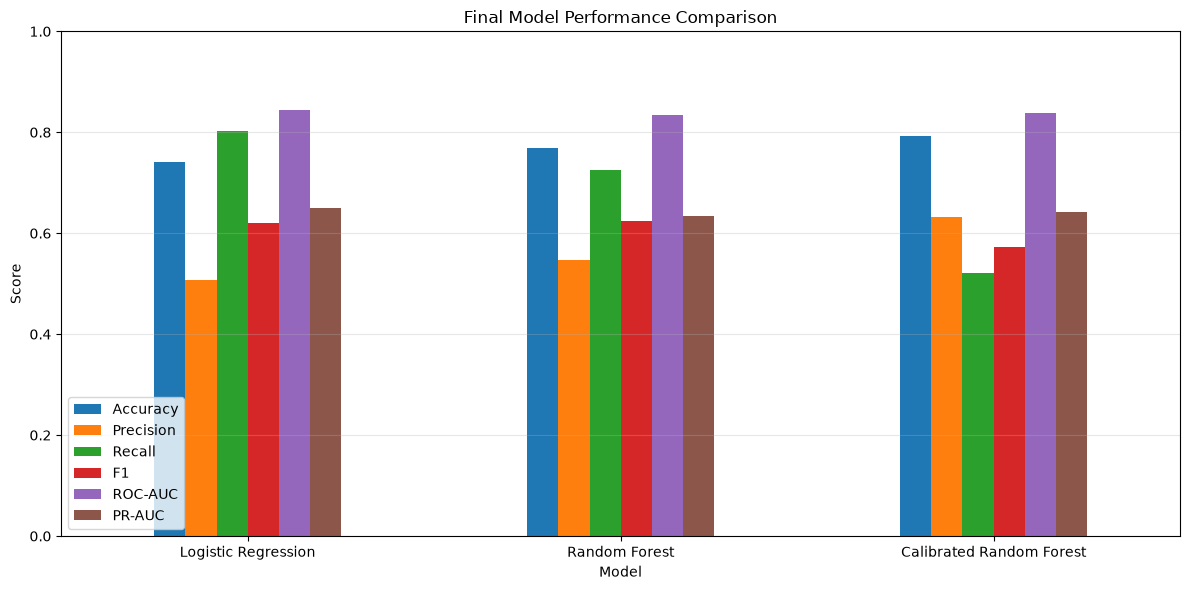

In [113]:
import matplotlib.pyplot as plt

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

plot_data = model_comparison.set_index("Model")[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Final Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower left")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [114]:
df["CalibratedChurnProbability"] = calibrated_research_rf.predict_proba(
    X_research
)[:, 1]

print(
    df[
        ["customerID", "ChurnProbability", "CalibratedChurnProbability"]
    ].head(10)
)

   customerID  ChurnProbability  CalibratedChurnProbability
0  7590-VHVEG          0.697969                    0.435287
1  5575-GNVDE          0.081108                    0.049034
2  3668-QPYBK          0.717327                    0.589157
3  7795-CFOCW          0.046284                    0.046100
4  9237-HQITU          0.835949                    0.742976
5  9305-CDSKC          0.957923                    0.828183
6  1452-KIOVK          0.672564                    0.456774
7  6713-OKOMC          0.363049                    0.155170
8  7892-POOKP          0.819396                    0.735637
9  6388-TABGU          0.073219                    0.049763


In [115]:
print("Original Churn Probability")
print(df["ChurnProbability"].describe())

print("\nCalibrated Churn Probability")
print(df["CalibratedChurnProbability"].describe())

Original Churn Probability
count    7043.000000
mean        0.393467
std         0.298903
min         0.001020
25%         0.107949
50%         0.346764
75%         0.665253
max         0.969786
Name: ChurnProbability, dtype: float64

Calibrated Churn Probability
count    7043.000000
mean        0.271800
std         0.253692
min         0.037577
25%         0.058239
50%         0.144488
75%         0.480294
max         0.834860
Name: CalibratedChurnProbability, dtype: float64


In [116]:
comparison = pd.DataFrame({
    "Original": df["ChurnProbability"],
    "Calibrated": df["CalibratedChurnProbability"]
})

print("\nProbability comparison:")
print(comparison.describe().round(4))


Probability comparison:
        Original  Calibrated
count  7043.0000   7043.0000
mean      0.3935      0.2718
std       0.2989      0.2537
min       0.0010      0.0376
25%       0.1079      0.0582
50%       0.3468      0.1445
75%       0.6653      0.4803
max       0.9698      0.8349


In [117]:
df["CalibratedRiskLevel"] = pd.cut(
    df["CalibratedChurnProbability"],
    bins=[-0.01, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

print(df["CalibratedRiskLevel"].value_counts())

CalibratedRiskLevel
Low       4513
Medium    1324
High      1206
Name: count, dtype: int64


In [118]:
print("\nOriginal Risk Distribution:")
print(df["MLRiskLevel"].value_counts())

print("\nCalibrated Risk Distribution:")
print(df["CalibratedRiskLevel"].value_counts())


Original Risk Distribution:
MLRiskLevel
Low       3262
High      2116
Medium    1665
Name: count, dtype: int64

Calibrated Risk Distribution:
CalibratedRiskLevel
Low       4513
Medium    1324
High      1206
Name: count, dtype: int64


In [119]:
risk_transition = pd.crosstab(
    df["MLRiskLevel"],
    df["CalibratedRiskLevel"],
    margins=True
)

print(risk_transition)

CalibratedRiskLevel   Low  Medium  High   All
MLRiskLevel                                  
Low                  3262       0     0  3262
Medium               1233     432     0  1665
High                   18     892  1206  2116
All                  4513    1324  1206  7043


In [120]:
risk_transition_pct = pd.crosstab(
    df["MLRiskLevel"],
    df["CalibratedRiskLevel"],
    normalize="index"
) * 100

print(risk_transition_pct.round(2))

CalibratedRiskLevel     Low  Medium   High
MLRiskLevel                               
Low                  100.00    0.00   0.00
Medium                74.05   25.95   0.00
High                   0.85   42.16  56.99


In [121]:
calibrated_risk_validation = df.groupby(
    "CalibratedRiskLevel",
    observed=True
)["ChurnFlag"].agg(
    ChurnRate="mean",
    Churners="sum",
    Customers="count"
)

calibrated_risk_validation["ChurnRate"] *= 100

print(
    calibrated_risk_validation.round(2)
)

                     ChurnRate  Churners  Customers
CalibratedRiskLevel                                
Low                       3.06       138       4513
Medium                   48.26       639       1324
High                     90.55      1092       1206


In [122]:
high_risk_churn_concentration = (
    calibrated_risk_validation.loc["High", "Churners"]
    / df["ChurnFlag"].sum()
    * 100
)

high_risk_customer_percentage = (
    calibrated_risk_validation.loc["High", "Customers"]
    / len(df)
    * 100
)

print(
    f"High-risk customers: "
    f"{high_risk_customer_percentage:.2f}% of customer base"
)

print(
    f"Actual churners captured in High-risk group: "
    f"{high_risk_churn_concentration:.2f}%"
)

High-risk customers: 17.12% of customer base
Actual churners captured in High-risk group: 58.43%


In [123]:
df["CalibratedRevenueAtRisk"] = (
    df["CalibratedChurnProbability"]
    * df["MonthlyCharges"]
)

print(
    df[
        [
            "customerID",
            "ChurnProbability",
            "CalibratedChurnProbability",
            "MonthlyCharges",
            "RevenueAtRisk",
            "CalibratedRevenueAtRisk"
        ]
    ].head(10)
)

   customerID  ChurnProbability  CalibratedChurnProbability  MonthlyCharges  \
0  7590-VHVEG          0.697969                    0.435287           29.85   
1  5575-GNVDE          0.081108                    0.049034           56.95   
2  3668-QPYBK          0.717327                    0.589157           53.85   
3  7795-CFOCW          0.046284                    0.046100           42.30   
4  9237-HQITU          0.835949                    0.742976           70.70   
5  9305-CDSKC          0.957923                    0.828183           99.65   
6  1452-KIOVK          0.672564                    0.456774           89.10   
7  6713-OKOMC          0.363049                    0.155170           29.75   
8  7892-POOKP          0.819396                    0.735637          104.80   
9  6388-TABGU          0.073219                    0.049763           56.15   

   RevenueAtRisk  CalibratedRevenueAtRisk  
0      20.834371                12.993317  
1       4.619123                 2.792485 

In [124]:
original_revenue_risk = df["RevenueAtRisk"].sum()

calibrated_revenue_risk = df["CalibratedRevenueAtRisk"].sum()

print(f"Original Expected Monthly Revenue Exposure: ${original_revenue_risk:,.2f}")
print(f"Calibrated Expected Monthly Revenue Exposure: ${calibrated_revenue_risk:,.2f}")

Original Expected Monthly Revenue Exposure: $202,507.30
Calibrated Expected Monthly Revenue Exposure: $140,561.90


In [125]:
revenue_risk_reduction = (
    (original_revenue_risk - calibrated_revenue_risk)
    / original_revenue_risk
    * 100
)

print(
    f"Reduction in Expected Monthly Revenue Exposure: "
    f"{revenue_risk_reduction:.2f}%"
)


Reduction in Expected Monthly Revenue Exposure: 30.59%


In [126]:
df["RevenueRiskScore"] = (
    df["CalibratedRevenueAtRisk"]
    / df["CalibratedRevenueAtRisk"].max()
)

df["CalibratedRetentionPriorityScore"] = (
    0.6 * df["CalibratedChurnProbability"]
    + 0.4 * df["RevenueRiskScore"]
)

print(
    df[
        [
            "customerID",
            "CalibratedChurnProbability",
            "CalibratedRevenueAtRisk",
            "RevenueRiskScore",
            "CalibratedRetentionPriorityScore"
        ]
    ].head(10)
)

   customerID  CalibratedChurnProbability  CalibratedRevenueAtRisk  \
0  7590-VHVEG                    0.435287                12.993317   
1  5575-GNVDE                    0.049034                 2.792485   
2  3668-QPYBK                    0.589157                31.726107   
3  7795-CFOCW                    0.046100                 1.950043   
4  9237-HQITU                    0.742976                52.528397   
5  9305-CDSKC                    0.828183                82.528462   
6  1452-KIOVK                    0.456774                40.698558   
7  6713-OKOMC                    0.155170                 4.616294   
8  7892-POOKP                    0.735637                77.094750   
9  6388-TABGU                    0.049763                 2.794209   

   RevenueRiskScore  CalibratedRetentionPriorityScore  
0          0.155931                          0.323544  
1          0.033512                          0.042825  
2          0.380739                          0.505790  
3    

In [127]:
df["CalibratedRetentionPriority"] = pd.cut(
    df["CalibratedRetentionPriorityScore"],
    bins=[-0.01, 0.25, 0.50, 0.75, 1.00],
    labels=["Low", "Moderate", "High", "Critical"]
)

print(df["CalibratedRetentionPriority"].value_counts())

CalibratedRetentionPriority
Low         4387
Moderate    1149
High        1052
Critical     455
Name: count, dtype: int64


In [128]:
calibrated_priority_validation = df.groupby(
    "CalibratedRetentionPriority",
    observed=True
)["ChurnFlag"].agg(
    ChurnRate="mean",
    Churners="sum",
    Customers="count"
)

calibrated_priority_validation["ChurnRate"] *= 100

print(calibrated_priority_validation.round(2))

                             ChurnRate  Churners  Customers
CalibratedRetentionPriority                                
Low                               3.10       136       4387
Moderate                         40.91       470       1149
High                             78.33       824       1052
Critical                         96.48       439        455


In [129]:
priority_revenue_analysis = df.groupby(
    "CalibratedRetentionPriority",
    observed=True
)["CalibratedRevenueAtRisk"].agg(
    TotalRevenueAtRisk="sum",
    AverageRevenueAtRisk="mean",
    Customers="count"
)

priority_revenue_analysis["PercentageOfTotalRisk"] = (
    priority_revenue_analysis["TotalRevenueAtRisk"]
    / df["CalibratedRevenueAtRisk"].sum()
    * 100
)

print(priority_revenue_analysis.round(2))

                             TotalRevenueAtRisk  AverageRevenueAtRisk  \
CalibratedRetentionPriority                                             
Low                                    25429.34                  5.80   
Moderate                               30396.47                 26.45   
High                                   53112.32                 50.49   
Critical                               31623.77                 69.50   

                             Customers  PercentageOfTotalRisk  
CalibratedRetentionPriority                                    
Low                               4387                  18.09  
Moderate                          1149                  21.62  
High                              1052                  37.79  
Critical                           455                  22.50  


In [130]:
critical_customers = df[
    df["CalibratedRetentionPriority"] == "Critical"
].copy()

critical_customers = critical_customers.sort_values(
    "CalibratedRevenueAtRisk",
    ascending=False
)

print(
    critical_customers[
        [
            "customerID",
            "tenure",
            "Contract",
            "InternetService",
            "MonthlyCharges",
            "CalibratedChurnProbability",
            "CalibratedRevenueAtRisk",
            "CalibratedRetentionPriorityScore",
            "Churn"
        ]
    ].head(20).to_string(index=False)
)

customerID  tenure       Contract InternetService  MonthlyCharges  CalibratedChurnProbability  CalibratedRevenueAtRisk  CalibratedRetentionPriorityScore Churn
5419-JPRRN       1 Month-to-month     Fiber optic          101.45                    0.821366                83.327605                          0.892820   Yes
2968-SSGAA      10 Month-to-month     Fiber optic          100.60                    0.826593                83.155263                          0.895129   Yes
4078-SAYYN      11 Month-to-month     Fiber optic          100.75                    0.823531                82.970699                          0.892405   Yes
4822-RVYBB       8 Month-to-month     Fiber optic          100.60                    0.824368                82.931377                          0.892719   Yes
0781-LKXBR       9 Month-to-month     Fiber optic          100.50                    0.823965                82.808454                          0.891887   Yes
3389-YGYAI       8 Month-to-month     Fiber op

In [131]:
top20_critical_risk = critical_customers.head(20)[
    "CalibratedRevenueAtRisk"
].sum()

total_critical_risk = critical_customers[
    "CalibratedRevenueAtRisk"
].sum()

print(
    f"Top 20 Critical customers' monthly revenue risk: "
    f"${top20_critical_risk:,.2f}"
)

print(
    f"Percentage of Critical-tier revenue risk: "
    f"{top20_critical_risk / total_critical_risk * 100:.2f}%"
)

Top 20 Critical customers' monthly revenue risk: $1,641.96
Percentage of Critical-tier revenue risk: 5.19%


In [132]:
print("X_test_research:", X_test_research.shape)
print("y_test_research:", y_test_research.shape)
print("Calibrated test probabilities:", calibrated_rf_proba.shape)

X_test_research: (1409, 22)
y_test_research: (1409,)
Calibrated test probabilities: (1409,)


In [133]:
import pandas as pd
import numpy as np

# Create test-set intervention analysis dataframe
intervention_df = pd.DataFrame({
    "ActualChurn": np.asarray(y_test_research),
    "ChurnProbability": calibrated_rf_proba
})

# Add MonthlyCharges from the research test set
intervention_df["MonthlyCharges"] = df.loc[
    X_test_research.index, "MonthlyCharges"
].values

# Expected monthly revenue at risk
intervention_df["RevenueAtRisk"] = (
    intervention_df["ChurnProbability"] *
    intervention_df["MonthlyCharges"]
)

# Rank customers by calibrated churn probability
intervention_df = intervention_df.sort_values(
    "ChurnProbability",
    ascending=False
).reset_index(drop=True)

# Resource allocation levels
target_percentages = [0.05, 0.10, 0.15, 0.20]

results = []

total_churners = intervention_df["ActualChurn"].sum()

for pct in target_percentages:

    n_target = int(np.ceil(len(intervention_df) * pct))

    targeted = intervention_df.head(n_target)

    actual_churners_targeted = targeted["ActualChurn"].sum()

    churners_captured_pct = (
        actual_churners_targeted / total_churners * 100
    )

    revenue_at_risk_targeted = targeted["RevenueAtRisk"].sum()

    churners_per_100_targeted = (
        actual_churners_targeted / n_target * 100
    )

    results.append({
        "TargetPercentage": pct * 100,
        "CustomersTargeted": n_target,
        "ActualChurnersTargeted": int(actual_churners_targeted),
        "ChurnersCapturedPct": churners_captured_pct,
        "ChurnersPer100Targeted": churners_per_100_targeted,
        "RevenueAtRiskTargeted": revenue_at_risk_targeted
    })

intervention_results = pd.DataFrame(results)

print("Retention Resource Allocation Analysis")
print("--------------------------------------")
print(intervention_results.to_string(index=False))

Retention Resource Allocation Analysis
--------------------------------------
 TargetPercentage  CustomersTargeted  ActualChurnersTargeted  ChurnersCapturedPct  ChurnersPer100Targeted  RevenueAtRiskTargeted
              5.0                 71                      56            14.973262               78.873239            4548.727689
             10.0                141                     107            28.609626               75.886525            8499.316030
             15.0                212                     150            40.106952               70.754717           11834.680064
             20.0                282                     184            49.197861               65.248227           14656.020247


In [134]:
# Apply the EXACT calibrated Revenue-Aware Retention Priority methodology
# to the held-out research test set

priority_test_df = intervention_df.copy()

# Use the calibrated revenue-at-risk scale from the existing full dataset
calibrated_revenue_risk_max = df["CalibratedRevenueAtRisk"].max()

print("Maximum calibrated revenue risk:", calibrated_revenue_risk_max)

# Revenue Risk Score
priority_test_df["RevenueRiskScore"] = (
    priority_test_df["RevenueAtRisk"] /
    calibrated_revenue_risk_max
)

# Same 60/40 weighting used by the existing project
priority_test_df["RetentionPriorityScore"] = (
    0.60 * priority_test_df["ChurnProbability"]
    + 0.40 * priority_test_df["RevenueRiskScore"]
)

# Rank by Revenue-Aware Retention Priority
priority_test_df = priority_test_df.sort_values(
    "RetentionPriorityScore",
    ascending=False
).reset_index(drop=True)

print("\nRevenue-Aware Retention Priority calculated successfully.")

print(
    priority_test_df[
        [
            "ActualChurn",
            "ChurnProbability",
            "MonthlyCharges",
            "RevenueAtRisk",
            "RevenueRiskScore",
            "RetentionPriorityScore"
        ]
    ].head(10).round(4)
)

Maximum calibrated revenue risk: 83.32760469863112

Revenue-Aware Retention Priority calculated successfully.
   ActualChurn  ChurnProbability  MonthlyCharges  RevenueAtRisk  \
0            1            0.8094           99.25        80.3363   
1            1            0.8182           95.45        78.0936   
2            1            0.7956          100.95        80.3182   
3            1            0.7881          101.95        80.3517   
4            1            0.8044           96.60        77.7058   
5            1            0.8099           94.20        76.2888   
6            1            0.7948           98.05        77.9317   
7            0            0.8072           94.10        75.9613   
8            1            0.8018           95.10        76.2490   
9            1            0.7942           95.15        75.5722   

   RevenueRiskScore  RetentionPriorityScore  
0            0.9641                  0.8713  
1            0.9372                  0.8658  
2            0

In [135]:
# ============================================================
# Probability-Only vs Revenue-Aware Retention Targeting
# ============================================================

target_percentages = [0.05, 0.10, 0.15, 0.20]

comparison_results = []

total_customers = len(priority_test_df)
total_churners = priority_test_df["ActualChurn"].sum()

# ------------------------------------------------------------
# Strategy A: Churn Probability
# ------------------------------------------------------------

probability_ranked = priority_test_df.sort_values(
    "ChurnProbability",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Strategy B: Revenue-Aware Retention Priority
# ------------------------------------------------------------

priority_ranked = priority_test_df.sort_values(
    "RetentionPriorityScore",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Evaluate both strategies at each resource level
# ------------------------------------------------------------

for pct in target_percentages:

    n_target = int(np.ceil(total_customers * pct))

    # ----- Probability-only targeting -----
    prob_targeted = probability_ranked.head(n_target)

    prob_churners = prob_targeted["ActualChurn"].sum()

    prob_capture = (
        prob_churners / total_churners * 100
    )

    prob_revenue = prob_targeted["RevenueAtRisk"].sum()

    prob_efficiency = (
        prob_churners / n_target * 100
    )

    # ----- Revenue-aware targeting -----
    priority_targeted = priority_ranked.head(n_target)

    priority_churners = priority_targeted["ActualChurn"].sum()

    priority_capture = (
        priority_churners / total_churners * 100
    )

    priority_revenue = priority_targeted["RevenueAtRisk"].sum()

    priority_efficiency = (
        priority_churners / n_target * 100
    )

    comparison_results.append({
        "TargetPercentage": pct * 100,
        "CustomersTargeted": n_target,

        "Probability_ChurnersCaptured":
            int(prob_churners),

        "Probability_CapturePct":
            prob_capture,

        "Probability_ChurnersPer100":
            prob_efficiency,

        "Probability_RevenueAtRisk":
            prob_revenue,

        "Priority_ChurnersCaptured":
            int(priority_churners),

        "Priority_CapturePct":
            priority_capture,

        "Priority_ChurnersPer100":
            priority_efficiency,

        "Priority_RevenueAtRisk":
            priority_revenue,

        "AdditionalRevenueRiskTargeted":
            priority_revenue - prob_revenue
    })

targeting_comparison = pd.DataFrame(comparison_results)

print("Probability-Only vs Revenue-Aware Retention Targeting")
print("=====================================================")

print(
    targeting_comparison.round(2).to_string(index=False)
)

Probability-Only vs Revenue-Aware Retention Targeting
 TargetPercentage  CustomersTargeted  Probability_ChurnersCaptured  Probability_CapturePct  Probability_ChurnersPer100  Probability_RevenueAtRisk  Priority_ChurnersCaptured  Priority_CapturePct  Priority_ChurnersPer100  Priority_RevenueAtRisk  AdditionalRevenueRiskTargeted
              5.0                 71                            56                   14.97                       78.87                    4548.73                         55                14.71                    77.46                 4837.88                         289.16
             10.0                141                           107                   28.61                       75.89                    8499.32                        105                28.07                    74.47                 8986.40                         487.09
             15.0                212                           150                   40.11                       70.75      

In [136]:
# ============================================================
# Quantifying the Churn Capture vs Financial Exposure Trade-off
# ============================================================

tradeoff = targeting_comparison.copy()

tradeoff["ChurnCaptureChangePct"] = (
    (
        tradeoff["Priority_CapturePct"]
        - tradeoff["Probability_CapturePct"]
    )
    / tradeoff["Probability_CapturePct"]
) * 100

tradeoff["RevenueRiskIncreasePct"] = (
    (
        tradeoff["Priority_RevenueAtRisk"]
        - tradeoff["Probability_RevenueAtRisk"]
    )
    / tradeoff["Probability_RevenueAtRisk"]
) * 100

tradeoff["Probability_RevenueRiskPerCustomer"] = (
    tradeoff["Probability_RevenueAtRisk"]
    / tradeoff["CustomersTargeted"]
)

tradeoff["Priority_RevenueRiskPerCustomer"] = (
    tradeoff["Priority_RevenueAtRisk"]
    / tradeoff["CustomersTargeted"]
)

tradeoff["Probability_RevenueRiskPerChurner"] = (
    tradeoff["Probability_RevenueAtRisk"]
    / tradeoff["Probability_ChurnersCaptured"]
)

tradeoff["Priority_RevenueRiskPerChurner"] = (
    tradeoff["Priority_RevenueAtRisk"]
    / tradeoff["Priority_ChurnersCaptured"]
)

print("Churn Capture vs Financial Exposure Trade-off")
print("==============================================")

print(
    tradeoff[
        [
            "TargetPercentage",
            "CustomersTargeted",
            "ChurnCaptureChangePct",
            "RevenueRiskIncreasePct",
            "Probability_RevenueRiskPerCustomer",
            "Priority_RevenueRiskPerCustomer",
            "Probability_RevenueRiskPerChurner",
            "Priority_RevenueRiskPerChurner"
        ]
    ].round(2).to_string(index=False)
)

Churn Capture vs Financial Exposure Trade-off
 TargetPercentage  CustomersTargeted  ChurnCaptureChangePct  RevenueRiskIncreasePct  Probability_RevenueRiskPerCustomer  Priority_RevenueRiskPerCustomer  Probability_RevenueRiskPerChurner  Priority_RevenueRiskPerChurner
              5.0                 71                  -1.79                    6.36                               64.07                            68.14                              81.23                           87.96
             10.0                141                  -1.87                    5.73                               60.28                            63.73                              79.43                           85.58
             15.0                212                  -5.33                    5.49                               55.82                            58.89                              78.90                           87.92
             20.0                282                  -2.17               

In [137]:
# ============================================================
# Sensitivity Analysis: Retention Priority Weighting
# ============================================================

weight_results = []

target_pct = 0.10
n_target = int(np.ceil(len(priority_test_df) * target_pct))
total_churners = priority_test_df["ActualChurn"].sum()

weight_configs = [
    (0.50, 0.50),
    (0.60, 0.40),
    (0.70, 0.30),
    (0.80, 0.20)
]

for churn_weight, revenue_weight in weight_configs:

    sensitivity_df = priority_test_df.copy()

    sensitivity_df["SensitivityScore"] = (
        churn_weight * sensitivity_df["ChurnProbability"]
        + revenue_weight * sensitivity_df["RevenueRiskScore"]
    )

    sensitivity_df = sensitivity_df.sort_values(
        "SensitivityScore",
        ascending=False
    ).reset_index(drop=True)

    targeted = sensitivity_df.head(n_target)

    churners_captured = targeted["ActualChurn"].sum()

    capture_pct = (
        churners_captured / total_churners * 100
    )

    revenue_targeted = targeted["RevenueAtRisk"].sum()

    churners_per_100 = (
        churners_captured / n_target * 100
    )

    revenue_per_customer = (
        revenue_targeted / n_target
    )

    weight_results.append({
        "ChurnWeight": churn_weight,
        "RevenueWeight": revenue_weight,
        "CustomersTargeted": n_target,
        "ChurnersCaptured": int(churners_captured),
        "ChurnCapturePct": capture_pct,
        "ChurnersPer100": churners_per_100,
        "RevenueAtRiskTargeted": revenue_targeted,
        "RevenueRiskPerCustomer": revenue_per_customer
    })

weight_sensitivity = pd.DataFrame(weight_results)

print("Retention Priority Weight Sensitivity Analysis")
print("================================================")

print(
    weight_sensitivity.round(2).to_string(index=False)
)

Retention Priority Weight Sensitivity Analysis
 ChurnWeight  RevenueWeight  CustomersTargeted  ChurnersCaptured  ChurnCapturePct  ChurnersPer100  RevenueAtRiskTargeted  RevenueRiskPerCustomer
         0.5            0.5                141               103            27.54           73.05                9031.37                   64.05
         0.6            0.4                141               105            28.07           74.47                8986.40                   63.73
         0.7            0.3                141               105            28.07           74.47                8932.05                   63.35
         0.8            0.2                141               105            28.07           74.47                8877.27                   62.96
